# (Failed) Initial attempts to train a NPE model

In [ ]:
from deepdiagnostics import models
from deepdiagnostics import data
from deepdiagnostics.utils.config import Config
from deepdiagnostics.utils.simulator_utils import register_simulator

from deepdiagnostics.plots import CDFRanks, CoverageFraction, Ranks, TARP, LC2ST

import yaml

In [ ]:
from deepdiagnostics.utils.defaults import Defaults

In [ ]:
Defaults

In [ ]:
! diagnose --model_path ../resources/savedmodels/sbi/sbi_linear_from_data.pkl --data_path ../resources/saveddata/data_validation.h5  --plots CoverageFraction

In [ ]:
import numpy as np
import torch

from sbi.utils import BoxUniform
from sbi.inference.base import infer
from sbi.inference import SNPE
from sbi.analysis import plot_summary
# from scripts import io, plot

In [ ]:
def simulator(thetas):#, percent_errors):
    # convert to numpy array (if tensor):
    thetas = np.atleast_2d(thetas)
    # Check if the input has the correct shape
    if thetas.shape[1] != 2:
        raise ValueError("Input tensor must have shape (n, 2) where n is the number of parameter sets.")

    # Unpack the parameters
    if thetas.shape[0] == 1:
        # If there's only one set of parameters, extract them directly
        m, b = thetas[0, 0], thetas[0, 1]
    else:
        # If there are multiple sets of parameters, extract them for each row
        m, b = thetas[:, 0], thetas[:, 1]
    x = np.linspace(0, 100, 101)
    rs = np.random.RandomState()#2147483648)# 
    # I'm thinking sigma could actually be a function of x
    # if we want to get fancy down the road
    # Generate random noise (epsilon) based on a normal distribution with mean 0 and standard deviation sigma
    sigma = 1
    ε = rs.normal(loc=0, scale=sigma, size=(len(x), thetas.shape[0]))
    
    # Initialize an empty array to store the results for each set of parameters
    y = np.zeros((len(x), thetas.shape[0]))
    for i in range(thetas.shape[0]):
        m, b = thetas[i, 0], thetas[i, 1]
        y[:, i] = m * x + b + ε[:, i]
    return torch.Tensor(y.T)

In [ ]:
# defining the prior distribution
low_bounds = torch.tensor([0, -10])
high_bounds = torch.tensor([10, 10])
prior = BoxUniform(low = low_bounds, high = high_bounds)
prior

In [ ]:
posterior = infer(simulator, prior, "SNPE", num_simulations=10000)

In [ ]:
plot_summary()

In [ ]:
modelloader = io.ModelLoader()
path = "../savedmodels/sbi/"
model_name = "nurs_sbi_model"
modelloader.save_model_pkl(path, model_name, posterior)

# A Working Example

In [ ]:
# the following lines of code are taken from https://sbi-dev.github.io/sbi/v0.23.3/tutorials/00_getting_started/
import numpy as np
import torch, pickle

from sbi.utils import BoxUniform
from sbi.inference import SNPE
from sbi.analysis import pairplot, plot_summary
from sbi.utils.user_input_checks import (
    check_sbi_inputs,
    process_prior,
    process_simulator,
)

In [ ]:
num_dim = 3

# simulator represents a model with parameters (theta)
def simulator(theta):
    # linear gaussian
    return theta + 1.0 + torch.randn_like(theta) * 0.1

# prior represents what's known about the data
prior = BoxUniform(low=-2 * torch.ones(num_dim), high=2 * torch.ones(num_dim))

In [ ]:
# Check prior, return PyTorch prior.
prior, num_parameters, prior_returns_numpy = process_prior(prior)

# Check simulator, returns PyTorch simulator able to simulate batches.
simulator = process_simulator(simulator, prior, prior_returns_numpy)

# Consistency check after making ready for sbi.
check_sbi_inputs(simulator, prior)

In [ ]:
print(f"Prior: {prior}")

In [ ]:
print(f"Number of parameters: {num_parameters}")

In [ ]:
print(f"Does prior return a Numpy data structure?: {prior_returns_numpy}")

In [ ]:
inference = SNPE(prior=prior)

In [ ]:
num_simulations = 20 # from sbi example, this was 2000
theta = prior.sample((num_simulations,))
x = simulator(theta) # here x represents simulated data and will be used to train the inference model
print("theta.shape", theta.shape)
print("x.shape", x.shape)

In [ ]:
theta[0]

In [ ]:
x[0]

In [ ]:
inference = inference.append_simulations(theta, x)
inference

In [ ]:
density_estimator = inference.train()

In [ ]:
# save model history after training (training and validation losses) but before inference
with open("/home/nurs/deepDiagnostics_RnD/DeepDiagnostics/notebooks/nurs_posterior_models/my_density_estimator.pkl", "wb") as handle:
    pickle.dump(density_estimator, handle)

In [ ]:
# load the saved model history
with open("/home/nurs/deepDiagnostics_RnD/DeepDiagnostics/notebooks/nurs_posterior_models/my_density_estimator.pkl", 'rb') as pkl_file:
    # Load the data from the file
    data = pickle.load(pkl_file)

In [ ]:
print(data)

In [ ]:
plot_summary(inference)

In [ ]:
plot_summary(inference, tags=["training_log_probs", "validation_log_probs"])

In [ ]:
posterior = inference.build_posterior(density_estimator)

print(posterior) # prints how the posterior was trained

In [ ]:
print(type(posterior))

## Running the inference model on observations

In [ ]:
theta_true = prior.sample((1,))
# generate our observation
x_obs = simulator(theta_true)

In [ ]:
samples = posterior.sample((10000,), x=x_obs)
_ = pairplot(samples,
             limits=[[-2, 2], [-2, 2], [-2, 2]],
             figsize=(6, 6),
             labels=[r"$\theta_1$", r"$\theta_2$", r"$\theta_3$"])

In [ ]:
samples = posterior.sample((10000,), x=x_obs)
pairplot(samples,
         points=theta_true,
         limits=[[-2, 2], [-2, 2], [-2, 2]], figsize=(6, 6),
         labels=[r"$\theta_1$", r"$\theta_2$", r"$\theta_3$"]);

In [ ]:
theta_posterior = posterior.sample((10000,), x=x_obs)  # sample from posterior
x_predictive = simulator(theta_posterior)  # simulate data from posterior
pairplot(x_predictive,
         points=x_obs,  # plot with x_obs as a point
         figsize=(6, 6),
         labels=[r"$x_1$", r"$x_2$", r"$x_3$"]);

## How to save a model

In [ ]:
# saving a trained model using pickle
!pwd
with open("/home/nurs/deepDiagnostics_RnD/DeepDiagnostics/notebooks/nurs_posterior_models/my_second_posterior.pkl", "wb") as handle:
    pickle.dump(posterior, handle)

## How to load a saved model

In [ ]:
!pwd

In [ ]:
# for loading one of the saved models in DeepDiagnostics 
# a few saved models are available at https://github.com/deepskies/DeepDiagnostics/tree/main/resources/savedmodels/sbi
import os
from deepdiagnostics import models

saved_models_loc = os.path.join(os.getcwd(), "../resources/savedmodels/sbi")
saved_models_loc = os.path.normpath(saved_models_loc)
saved_model = os.path.join(saved_models_loc, "sbi_linear_from_data.pkl")

model = models.SBIModel(saved_model)

In [ ]:
model.posterior

In [ ]:
# for loading a saved model external to DeepDiagnostics
import pickle
from pathlib import Path

saved_models_loc = Path("../resources/savedmodels/sbi") # this returns the relative path
# saved_models_loc = Path("../resources/savedmodels/sbi").absolute # this returns the relative path
# print(saved_models_loc.absolute()) # does not normalize . and .. components
saved_models_loc = saved_models_loc.resolve()

pkl_file_path = saved_models_loc / 'sbi_linear_from_data.pkl'  # Replace with the actual path to your .pkl file
print(f"Pickle file at: {pkl_file_path}")
with open(pkl_file_path, 'rb') as pkl_file:
    # Load the data from the file
    data = pickle.load(pkl_file)

In [ ]:
print(data)

# Example for preserving model's training history

In [11]:
# the following lines of code are taken from https://sbi-dev.github.io/sbi/v0.23.3/tutorials/00_getting_started/
import numpy as np
import torch, pickle

from sbi.utils import BoxUniform
from sbi.inference import SNPE
from sbi.analysis import pairplot, plot_summary

In [12]:
num_dim = 3

# simulator represents a model with parameters (theta)
def simulator(theta):
    # linear gaussian
    return theta + 1.0 + torch.randn_like(theta) * 0.1

# prior represents what's known about the data
prior = BoxUniform(low=-2 * torch.ones(num_dim), high=2 * torch.ones(num_dim))

In [13]:
inference = SNPE(prior=prior)

In [14]:
num_simulations = 200 # from sbi example, this was 2000
theta = prior.sample((num_simulations,))
x = simulator(theta) # here x represents simulated data and will be used to train the inference model
print("theta.shape", theta.shape)
print("x.shape", x.shape)

theta.shape torch.Size([200, 3])
x.shape torch.Size([200, 3])


In [15]:
inference = inference.append_simulations(theta, x)
inference

In [16]:
density_estimator = inference.train(show_train_summary=True)

 Neural network successfully converged after 312 epochs.
        -------------------------
        ||||| ROUND 1 STATS |||||:
        -------------------------
        Epochs trained: 312
        Best validation performance: 2.2746
        -------------------------
        


In [17]:
type(density_estimator)

nflows.flows.base.Flow

In [18]:
density_estimator

Flow(
  (_transform): CompositeTransform(
    (_transforms): ModuleList(
      (0): AffineTransform()
      (1): MaskedAffineAutoregressiveTransform(
        (autoregressive_net): MADE(
          (initial_layer): MaskedLinear(in_features=3, out_features=50, bias=True)
          (context_layer): Linear(in_features=3, out_features=50, bias=True)
          (blocks): ModuleList(
            (0-1): 2 x MaskedFeedforwardBlock(
              (linear): MaskedLinear(in_features=50, out_features=50, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
          )
          (final_layer): MaskedLinear(in_features=50, out_features=6, bias=True)
        )
      )
      (2): RandomPermutation()
      (3): MaskedAffineAutoregressiveTransform(
        (autoregressive_net): MADE(
          (initial_layer): MaskedLinear(in_features=3, out_features=50, bias=True)
          (context_layer): Linear(in_features=3, out_features=50, bias=True)
          (blocks): ModuleList(
       

## Manipulating training history of the model

In [ ]:
import matplotlib.pyplot as plt
# from Roy Zhao:
# plt.plot(inference['training_loss'], label='Training')
# plt.plot(inference['validation_loss'], label='Validation')

# with sbi v0.22.0, the above approach to access the training history has changed 
# the sbi toolkit now provides the summary attribute that contains the training history 
inference.summary

In [ ]:
type(inference.summary)

In [ ]:
inference.summary.keys()

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, inference.summary['epochs_trained'][0]+1)
train_loss_history = inference.summary['training_log_probs']
val_loss_history = inference.summary['validation_log_probs']
best_loss = inference.summary['best_validation_log_prob']

plt.plot(epochs, train_loss_history, label='Training Loss')
plt.plot(epochs, val_loss_history, label='Validation Loss')
plt.axhline(y=best_loss, color='m', linestyle='--', label=f'Best Val Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Validation Loss Over Epochs')

plt.legend()
plt.grid()
plt.show()

In [ ]:
# save model history after training (training and validation losses) but before inference
with open("/home/nurs/deepDiagnostics_RnD/DeepDiagnostics/notebooks/nurs_posterior_models/my_density_estimator_with_train_summary.pkl", "wb") as handle:
    pickle.dump(density_estimator, handle)

In [ ]:
posterior = inference.build_posterior(density_estimator)

In [ ]:
type(posterior)

In [ ]:
posterior

In [ ]:
type(inference.append_simulations(theta, x))

In [ ]:
!pip list

In [ ]:
# load the saved model history
import pickle
with open("/home/nurs/deepDiagnostics_RnD/DeepDiagnostics/notebooks/nurs_posterior_models/my_density_estimator.pkl", 'rb') as pkl_file:
    # Load the data from the file
    data = pickle.load(pkl_file)

In [ ]:
!pwd

In [ ]:
import pandas as pd
from tbparse import SummaryReader
pd.set_option('display.max_rows', None)
log_dir = "/home/nurs/deepDiagnostics_RnD/DeepDiagnostics/notebooks/sbi-logs/SNPE_C/2025-08-21T18_41_01.511276"
reader = SummaryReader(log_dir) # by default, events stored in LONG format (pivot=False)
df = reader.scalars
print(df)

In [ ]:
import pandas as pd
from tbparse import SummaryReader
pd.set_option('display.max_rows', None)
log_dir = "/home/nurs/deepDiagnostics_RnD/DeepDiagnostics/notebooks/sbi-logs/SNPE_C/2025-08-21T18_41_01.511276"
reader = SummaryReader(log_dir, pivot=True) # events stored in WIDE format (pivot=True)
df = reader.scalars
print(df)

# Working Example from save_and_load_data.ipynb

In [ ]:
import numpy as np
from sbi.utils import BoxUniform
# from sbi.inference import SNPE
# from sbi.inference.base import infer
# from sbi.analysis import pairplot
# import torch

In [ ]:
def simulator(thetas):#, percent_errors):
    # convert to numpy array (if tensor):
    thetas = np.atleast_2d(thetas)
    # Check if the input has the correct shape
    if thetas.shape[1] != 2:
        raise ValueError("Input tensor must have shape (n, 2) where n is the number of parameter sets.")

    # Unpack the parameters
    if thetas.shape[0] == 1:
        # If there's only one set of parameters, extract them directly
        m, b = thetas[0, 0], thetas[0, 1]
    else:
        # If there are multiple sets of parameters, extract them for each row
        m, b = thetas[:, 0], thetas[:, 1]
    x = np.linspace(0, 100, 101)
    rs = np.random.RandomState()#2147483648)# 
    # I'm thinking sigma could actually be a function of x
    # if we want to get fancy down the road
    # Generate random noise (epsilon) based on a normal distribution with mean 0 and standard deviation sigma
    sigma = 5
    ε = rs.normal(loc=0, scale=sigma, size=(len(x), thetas.shape[0]))
    
    # Initialize an empty array to store the results for each set of parameters
    y = np.zeros((len(x), thetas.shape[0]))
    for i in range(thetas.shape[0]):
        m, b = thetas[i, 0], thetas[i, 1]
        y[:, i] = m * x + b + ε[:, i]
    return torch.Tensor(y.T)

## Define the range of parameters (Prior)

In [ ]:
low_bounds = torch.tensor([0, -10])
high_bounds = torch.tensor([10, 10])

prior = BoxUniform(low = low_bounds, high = high_bounds)

To create the training set, sample from this prior and run it through the simulator.

In [ ]:
params = prior.sample((10000,))
xs = simulator(params)

In [ ]:
print(f"Thetas: {params}")

In [ ]:
print(f"X: {xs}")

# For Development/Testing [issue#138 - loss function](https://github.com/deepskies/DeepDiagnostics/issues/138)

In [21]:
inference.summary

{'epochs_trained': [312],
 'best_validation_log_prob': [2.274601364135742],
 'validation_log_probs': [-8.496188354492187,
  -8.25677719116211,
  -8.01808853149414,
  -7.776371002197266,
  -7.529073333740234,
  -7.274382019042969,
  -7.012332153320313,
  -6.744195556640625,
  -6.471495056152344,
  -6.200408554077148,
  -5.939179611206055,
  -5.695995330810547,
  -5.4784690856933596,
  -5.282917022705078,
  -5.0954841613769535,
  -4.894858551025391,
  -4.667083740234375,
  -4.416940689086914,
  -4.143952560424805,
  -3.8561878204345703,
  -3.5596351623535156,
  -3.2561214447021483,
  -2.9507904052734375,
  -2.6407398223876952,
  -2.3633901596069338,
  -2.059286117553711,
  -1.7646713256835938,
  -1.4835969924926757,
  -1.253831672668457,
  -1.0239995956420898,
  -0.905454158782959,
  -0.9281070709228516,
  -0.6479008197784424,
  -0.5728958129882813,
  -0.5637442111968994,
  -0.4716936111450195,
  -0.5201590061187744,
  -0.40235490798950196,
  -0.2802121162414551,
  -0.23854496479034423,


In [19]:
from deepdiagnostics.plots.lossPlot import LossPlot

loss_curves = LossPlot()
# dir(loss_curves)

Epochs = None
Best validation loss = None
Number of epochs determined: 312
Best validation loss found: -8.496188354492187


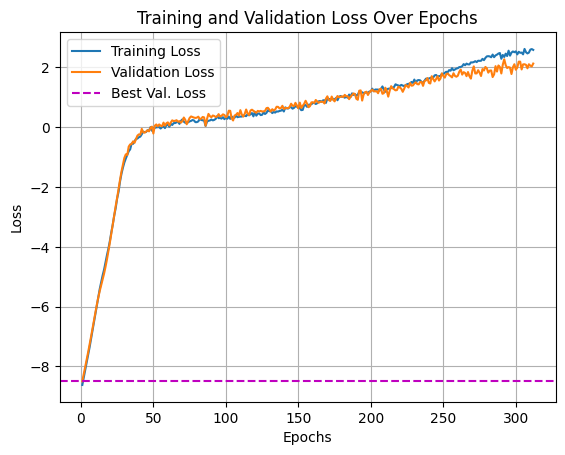

In [20]:
loss_history = dict()
loss_history["train_loss"] = inference.summary['training_log_probs']
loss_history["val_loss"] = inference.summary['validation_log_probs']
best_val_loss = inference.summary['best_validation_log_prob']
loss_curves.plot(loss_history)

In [1]:
training_history = {'epochs_trained': [312],
 'best_validation_log_prob': [2.274601364135742],
 'validation_log_probs': [-8.496188354492187,
  -8.25677719116211,
  -8.01808853149414,
  -7.776371002197266,
  -7.529073333740234,
  -7.274382019042969,
  -7.012332153320313,
  -6.744195556640625,
  -6.471495056152344,
  -6.200408554077148,
  -5.939179611206055,
  -5.695995330810547,
  -5.4784690856933596,
  -5.282917022705078,
  -5.0954841613769535,
  -4.894858551025391,
  -4.667083740234375,
  -4.416940689086914,
  -4.143952560424805,
  -3.8561878204345703,
  -3.5596351623535156,
  -3.2561214447021483,
  -2.9507904052734375,
  -2.6407398223876952,
  -2.3633901596069338,
  -2.059286117553711,
  -1.7646713256835938,
  -1.4835969924926757,
  -1.253831672668457,
  -1.0239995956420898,
  -0.905454158782959,
  -0.9281070709228516,
  -0.6479008197784424,
  -0.5728958129882813,
  -0.5637442111968994,
  -0.4716936111450195,
  -0.5201590061187744,
  -0.40235490798950196,
  -0.2802121162414551,
  -0.23854496479034423,
  -0.24994056224822997,
  -0.05394519567489624,
  -0.17049884796142578,
  -0.1801762819290161,
  -0.14414598941802978,
  -0.09926973581314087,
  -0.13784434795379638,
  -0.01952606439590454,
  0.019643163681030272,
  -0.20959241390228273,
  0.050979650020599364,
  0.09466127157211304,
  0.028169405460357667,
  0.09527890682220459,
  0.05167725086212158,
  0.033858883380889895,
  0.15568498373031617,
  0.05203022956848145,
  0.13408365249633789,
  0.16406667232513428,
  0.06313416957855225,
  0.15899949073791503,
  0.2306217670440674,
  0.20784354209899902,
  0.2159480094909668,
  0.23563027381896973,
  0.1863027572631836,
  0.2042771339416504,
  0.15369977951049804,
  0.2054048538208008,
  0.3255345106124878,
  0.25044066905975343,
  0.10042980909347535,
  0.20285530090332032,
  0.310845947265625,
  0.36114332675933836,
  0.34321036338806155,
  0.3236220836639404,
  0.312426495552063,
  0.3221458673477173,
  0.35399699211120605,
  0.2765862464904785,
  0.2879922866821289,
  0.34467623233795164,
  0.33010504245758054,
  0.04974573850631714,
  0.2788347005844116,
  0.4471385955810547,
  0.3718149662017822,
  0.33533263206481934,
  0.39316961765289304,
  0.3769311189651489,
  0.3421871900558472,
  0.36142544746398925,
  0.43859333992004396,
  0.3610752820968628,
  0.38408260345458983,
  0.43167667388916015,
  0.410800838470459,
  0.3321802616119385,
  0.3809230327606201,
  0.5531305313110352,
  0.5506388187408447,
  0.29737584590911864,
  0.22698004245758058,
  0.3914116382598877,
  0.4160278797149658,
  0.4755570888519287,
  0.3916025638580322,
  0.5726328372955323,
  0.42302908897399905,
  0.35557708740234373,
  0.4474808692932129,
  0.5937908172607422,
  0.4653653621673584,
  0.40552854537963867,
  0.5604465961456299,
  0.5874764919281006,
  0.5501972198486328,
  0.5121404647827148,
  0.485538387298584,
  0.5476620674133301,
  0.5283769607543946,
  0.5476442813873291,
  0.5272037506103515,
  0.5325408935546875,
  0.5431941032409668,
  0.6399035453796387,
  0.65137939453125,
  0.5863508224487305,
  0.5257540225982666,
  0.6040197849273682,
  0.5606235980987548,
  0.5923035621643067,
  0.6856060028076172,
  0.6827571868896485,
  0.632700777053833,
  0.6438763618469239,
  0.7178073406219483,
  0.61015625,
  0.6432008266448974,
  0.6442322731018066,
  0.6384374141693115,
  0.6799153327941895,
  0.7879138946533203,
  0.7218723297119141,
  0.7082286834716797,
  0.8174541473388672,
  0.7296904563903809,
  0.6347572326660156,
  0.8256707191467285,
  0.6442337989807129,
  0.7197895050048828,
  0.7825232028961182,
  0.8862577438354492,
  0.7907185554504395,
  0.6700421333312988,
  0.705817699432373,
  0.8321973800659179,
  0.8377820968627929,
  0.8135165214538574,
  0.9117287635803223,
  0.8634939193725586,
  0.8174569129943847,
  0.852863883972168,
  0.8536674499511718,
  0.8537422180175781,
  0.7957908630371093,
  0.9553244590759278,
  1.0350663185119628,
  0.9103046417236328,
  0.8785275459289551,
  1.027144432067871,
  0.9202445030212403,
  0.8661561965942383,
  0.9631061553955078,
  1.0461299896240235,
  1.0038749694824218,
  1.0171286582946777,
  1.0352416038513184,
  1.0093950271606444,
  1.0846855163574218,
  1.0358054161071777,
  1.0400126457214356,
  0.9406030654907227,
  1.0204647064208985,
  1.0729005813598633,
  1.131716823577881,
  1.1134461402893066,
  0.9525872230529785,
  0.9195306777954102,
  1.2223939895629883,
  1.2331045150756836,
  0.8921653747558593,
  1.0906620025634766,
  1.1706356048583983,
  1.1893350601196289,
  1.0794065475463868,
  1.1652094841003418,
  1.208697509765625,
  1.2599058151245117,
  1.2067729949951171,
  1.2006359100341797,
  1.2045669555664062,
  1.1390352249145508,
  1.2730677604675293,
  1.2874319076538085,
  1.1191396713256836,
  1.1419842720031739,
  1.3231063842773438,
  1.2114521980285644,
  1.0241525650024415,
  1.2236299514770508,
  1.374307632446289,
  1.3046772956848145,
  1.2741267204284668,
  1.2342918395996094,
  1.2449288368225098,
  1.3576581001281738,
  1.3301799774169922,
  1.2878787040710449,
  1.1856857299804688,
  1.2884943008422851,
  1.4137812614440919,
  1.3782301902770997,
  1.3292160034179688,
  1.4842536926269532,
  1.3908119201660156,
  1.3981619834899903,
  1.460587978363037,
  1.5040688514709473,
  1.4440082550048827,
  1.4345926284790038,
  1.5116159439086914,
  1.5189897537231445,
  1.3848827362060547,
  1.5459797859191895,
  1.56744384765625,
  1.646194076538086,
  1.483797264099121,
  1.4643310546875,
  1.7088035583496093,
  1.616185760498047,
  1.5340078353881836,
  1.6108909606933595,
  1.7070978164672852,
  1.5640308380126953,
  1.6282209396362304,
  1.8040016174316407,
  1.7186025619506835,
  1.6605899810791016,
  1.7745479583740233,
  1.7988039016723634,
  1.7448204040527344,
  1.711649513244629,
  1.6688432693481445,
  1.80737247467041,
  1.717747688293457,
  1.6908130645751953,
  1.7251121520996093,
  1.8582649230957031,
  1.931002426147461,
  1.7609506607055665,
  1.8434123992919922,
  1.816478157043457,
  1.7090816497802734,
  1.8471158981323241,
  1.706863021850586,
  1.6278507232666015,
  1.8926406860351563,
  2.0368900299072266,
  1.7998645782470704,
  1.8018438339233398,
  1.9093137741088868,
  1.8258651733398437,
  1.7144821166992188,
  1.9463823318481446,
  1.8990251541137695,
  2.017098617553711,
  1.972416305541992,
  1.8271596908569336,
  1.8965970993041992,
  1.8996879577636718,
  1.6796842575073243,
  1.768319320678711,
  2.0444429397583006,
  1.8623622894287108,
  2.066975975036621,
  2.0145496368408202,
  1.7991758346557618,
  2.094401168823242,
  2.274601364135742,
  2.0791854858398438,
  1.9815460205078126,
  2.0129684448242187,
  1.9952518463134765,
  1.7805879592895508,
  2.0086061477661135,
  2.1086614608764647,
  1.9241533279418945,
  1.9957904815673828,
  2.1940990447998048,
  2.1946640014648438,
  1.9337158203125,
  2.1035589218139648,
  2.107088088989258,
  2.0883323669433596,
  1.9725055694580078,
  2.1071041107177733,
  2.060932922363281,
  2.035808563232422,
  2.1310285568237304],
 'training_log_probs': [-8.619363810221355,
  -8.369719848632812,
  -8.121584065755208,
  -7.878519287109375,
  -7.622638142903646,
  -7.362890218098959,
  -7.084885050455729,
  -6.814575602213542,
  -6.541867472330729,
  -6.252056681315104,
  -5.961289265950521,
  -5.674836629231771,
  -5.412246500651042,
  -5.189400126139323,
  -4.957445983886719,
  -4.762341918945313,
  -4.515734659830729,
  -4.275242411295573,
  -4.059109700520834,
  -3.804912414550781,
  -3.5139365641276044,
  -3.253029276529948,
  -2.952592366536458,
  -2.7059173583984375,
  -2.384599812825521,
  -2.156404317220052,
  -1.8165769958496094,
  -1.556371307373047,
  -1.351910654703776,
  -1.1783092498779297,
  -1.0454664103190103,
  -0.9289424641927083,
  -0.8034132385253906,
  -0.7390872192382812,
  -0.541656608581543,
  -0.5553345998128255,
  -0.47286219278971353,
  -0.3878428141276042,
  -0.3775111198425293,
  -0.33471805572509766,
  -0.3121492640177409,
  -0.23538231372833252,
  -0.1446381425857544,
  -0.16450340112050374,
  -0.156699800491333,
  -0.10036052544911703,
  -0.118203600247701,
  0.0030468924840291343,
  -0.11635903676350912,
  -0.030970584551493326,
  -0.020821304321289064,
  -0.003757642110188802,
  0.003156325022379557,
  0.00590754508972168,
  -0.04184428532918294,
  0.004017480214436849,
  0.026646056175231934,
  -0.027230669657389323,
  0.07519826889038086,
  0.08806771278381348,
  0.014248418807983398,
  0.11341149012247721,
  0.0761660083134969,
  0.1396657911936442,
  0.14063153425852457,
  0.16557498296101889,
  0.18174975713094074,
  0.11339121341705322,
  0.21426513036092124,
  0.26316275278727214,
  0.18768462498982746,
  0.14907005151112873,
  0.1511782948176066,
  0.16623130639394124,
  0.1975829569498698,
  0.21274036407470703,
  0.24170503457387288,
  0.2286035410563151,
  0.17104016621907553,
  0.17134896596272786,
  0.19672425270080565,
  0.28397115707397463,
  0.2439792760213216,
  0.23254470666249594,
  0.22939662933349608,
  0.04278911590576172,
  0.18661835829416912,
  0.21817114512125652,
  0.22727504412333172,
  0.25848844528198245,
  0.22982563654581706,
  0.24743502298990885,
  0.28071521441141767,
  0.3722010294596354,
  0.30398741404215496,
  0.31145349502563474,
  0.2882563829421997,
  0.33872439702351886,
  0.2699316914876302,
  0.32054027875264485,
  0.28318769454956055,
  0.3578710492451986,
  0.28099156697591143,
  0.35900362650553386,
  0.317015495300293,
  0.3196274503072103,
  0.4010495376586914,
  0.33611255645751953,
  0.35010078430175784,
  0.3577204895019531,
  0.35817108154296873,
  0.39178129196166994,
  0.38352678934733075,
  0.37191446940104167,
  0.44155192057291665,
  0.39910162607828775,
  0.432227783203125,
  0.47467198689778645,
  0.364528538386027,
  0.5184199396769206,
  0.38791540145874026,
  0.4514391326904297,
  0.46330755869547524,
  0.4070786730448405,
  0.4162087694803874,
  0.4989208094278971,
  0.4432818603515625,
  0.4802464803059896,
  0.5708230336507162,
  0.5344392522176107,
  0.5399438858032226,
  0.47319644927978516,
  0.5119633611043294,
  0.49053858439127607,
  0.5304894320170085,
  0.5245828755696614,
  0.5452253087361654,
  0.5546458689371745,
  0.5897821299235027,
  0.527974116007487,
  0.6656837336222331,
  0.6300880686442057,
  0.628338114420573,
  0.6680856068929036,
  0.6728833643595378,
  0.6212813695271809,
  0.6489807001749675,
  0.7037134424845377,
  0.6920054499308268,
  0.6471598307291667,
  0.640308952331543,
  0.5721821657816569,
  0.5793822097778321,
  0.7437381235758463,
  0.741703389485677,
  0.682320442199707,
  0.7499761199951172,
  0.7619697062174479,
  0.7710893249511719,
  0.8108180745442708,
  0.8129830678304036,
  0.778173090616862,
  0.8036583201090495,
  0.8685925801595052,
  0.8795687866210937,
  0.8502368672688803,
  0.9005497868855794,
  0.9045052337646484,
  0.8150104268391927,
  0.9536018117268881,
  0.9480615234375,
  0.9384334818522135,
  0.9329793548583984,
  0.9492239125569661,
  0.9280506642659505,
  0.9817738850911458,
  0.9044999694824218,
  1.0101520029703777,
  1.0461713409423827,
  1.0198440297444662,
  1.0222005971272787,
  0.9888811747233073,
  1.0203761800130209,
  0.9877936553955078,
  1.0940970865885418,
  1.0087744903564453,
  1.1337110646565756,
  1.081415532430013,
  1.1100623067220052,
  1.055827662150065,
  1.0912862141927084,
  1.1909086100260418,
  1.1589102172851562,
  1.1709337361653647,
  1.140640411376953,
  1.156976801554362,
  1.1602278645833333,
  1.1570267232259115,
  1.1950331115722657,
  1.201091512044271,
  1.2910230000813803,
  1.2035281372070312,
  1.2626739501953126,
  1.260579350789388,
  1.2606473541259766,
  1.2238660685221354,
  1.2843894958496094,
  1.3659073384602864,
  1.2584840647379558,
  1.1873496246337891,
  1.2652894337972005,
  1.2892464192708333,
  1.2911715443929037,
  1.3111559549967449,
  1.319530537923177,
  1.3470122782389322,
  1.437161865234375,
  1.4136065165201823,
  1.3965232849121094,
  1.3808462015787761,
  1.4169970194498698,
  1.393916269938151,
  1.3777692667643229,
  1.4117451477050782,
  1.4386511739095051,
  1.453037821451823,
  1.4562240600585938,
  1.516886952718099,
  1.483074239095052,
  1.5953983561197917,
  1.4813878885904948,
  1.5669090779622397,
  1.5795801798502604,
  1.5700557963053385,
  1.5123159535725912,
  1.4891688028971355,
  1.5540399169921875,
  1.6245497639973958,
  1.6221080525716145,
  1.6299092610677084,
  1.6487502034505208,
  1.6635652669270833,
  1.6644090779622396,
  1.7362375895182292,
  1.7483435567220051,
  1.703162638346354,
  1.7110170491536458,
  1.7157935587565105,
  1.7898232523600262,
  1.7766006469726563,
  1.820704854329427,
  1.8566998799641927,
  1.842245127360026,
  1.9116643778483073,
  1.8922960917154947,
  1.9757855224609375,
  1.9055599466959636,
  1.9327056884765625,
  1.9643391927083333,
  1.9763425699869792,
  2.011994171142578,
  2.017999013264974,
  2.0412694803873697,
  2.11273188273112,
  2.0748308817545573,
  2.1292052205403644,
  2.1039073181152346,
  2.1029342651367187,
  2.169890899658203,
  2.168426615397135,
  2.1808587646484376,
  2.211004892985026,
  2.1798412068684896,
  2.2262838236490885,
  2.221402842203776,
  2.223360544840495,
  2.289256591796875,
  2.2438850911458332,
  2.3197810872395834,
  2.371450958251953,
  2.378226725260417,
  2.3701820373535156,
  2.3417115783691407,
  2.431795857747396,
  2.3444284057617186,
  2.403301798502604,
  2.429200948079427,
  2.4663787841796876,
  2.4843412272135414,
  2.2907997131347657,
  2.4181707763671874,
  2.3514417012532554,
  2.4627362569173177,
  2.3834610493977864,
  2.5623263041178386,
  2.395570068359375,
  2.4989024861653646,
  2.5350988260904948,
  2.5111541239420574,
  2.539444580078125,
  2.437586212158203,
  2.5256326802571616,
  2.4905262247721356,
  2.4980918884277346,
  2.438987070719401,
  2.6206847127278645,
  2.511552937825521,
  2.46954106648763,
  2.497131805419922,
  2.597748006184896,
  2.6156546020507814,
  2.587898457845052],
 'epoch_durations_sec': [5.443612098693848,
  3.1529955863952637,
  5.810685157775879,
  5.403539419174194,
  2.369164228439331,
  13.233171939849854,
  23.054399490356445,
  22.97557520866394,
  1.9979197978973389,
  4.727239608764648,
  13.861778497695923,
  4.820910692214966,
  7.394470691680908,
  11.26876187324524,
  1.5946199893951416,
  1.424337387084961,
  2.080784797668457,
  2.3910434246063232,
  5.60759973526001,
  4.886847496032715,
  7.505399465560913,
  4.1322314739227295,
  1.857478380203247,
  4.623675107955933,
  10.102566957473755,
  8.994491815567017,
  6.59378719329834,
  6.022421360015869,
  5.701116323471069,
  8.807045698165894,
  2.1521501541137695,
  5.297300577163696,
  5.5265350341796875,
  8.600900888442993,
  5.867379188537598,
  14.323936462402344,
  23.165684938430786,
  16.148674964904785,
  3.7300732135772705,
  4.5346760749816895,
  23.25800657272339,
  22.826570987701416,
  5.6892619132995605,
  3.177129030227661,
  2.2988884449005127,
  5.699767589569092,
  2.739541530609131,
  5.1915576457977295,
  11.362799167633057,
  11.328453540802002,
  1.6650800704956055,
  4.204648494720459,
  1.5305650234222412,
  10.86379098892212,
  4.422616004943848,
  5.1387434005737305,
  1.9890191555023193,
  4.197985887527466,
  8.66840934753418,
  11.100041389465332,
  2.6208677291870117,
  4.091511964797974,
  7.878749370574951,
  4.205806255340576,
  15.430124521255493,
  2.458315849304199,
  1.5185301303863525,
  4.201408863067627,
  11.105565547943115,
  10.394315958023071,
  1.9717953205108643,
  4.534998893737793,
  5.160003423690796,
  6.541527271270752,
  4.981680154800415,
  7.000603437423706,
  10.70266056060791,
  3.904597759246826,
  6.101088285446167,
  3.0280020236968994,
  4.070627927780151,
  1.4258863925933838,
  5.37221622467041,
  2.3990654945373535,
  3.81158709526062,
  12.324116706848145,
  6.282843112945557,
  11.816821336746216,
  2.8888823986053467,
  17.187748193740845,
  22.709216833114624,
  10.297297239303589,
  19.579806566238403,
  5.199159383773804,
  1.934762954711914,
  9.387756586074829,
  8.905610799789429,
  7.686326265335083,
  5.803267478942871,
  3.6013402938842773,
  6.802665948867798,
  11.09098482131958,
  5.367382526397705,
  8.730622053146362,
  2.478088140487671,
  3.7322309017181396,
  5.767263889312744,
  7.624135732650757,
  3.495073080062866,
  5.908513784408569,
  12.498754024505615,
  9.395723819732666,
  14.281482219696045,
  7.985907793045044,
  8.384307861328125,
  2.6999971866607666,
  2.828338146209717,
  5.896345376968384,
  7.110986948013306,
  2.335965394973755,
  5.517327547073364,
  2.9834258556365967,
  5.699022531509399,
  1.6989219188690186,
  5.899592399597168,
  10.9378023147583,
  5.869140148162842,
  6.639434337615967,
  11.246360301971436,
  7.625643491744995,
  15.569101572036743,
  17.09960412979126,
  5.835705518722534,
  1.9027378559112549,
  3.9939019680023193,
  2.081818103790283,
  12.99906301498413,
  10.715593814849854,
  14.261498928070068,
  3.702486753463745,
  9.144149780273438,
  5.055144309997559,
  2.7146694660186768,
  8.184125661849976,
  6.089701414108276,
  6.426233291625977,
  5.078583240509033,
  6.788904905319214,
  10.132381439208984,
  1.885908603668213,
  5.9744322299957275,
  5.095240831375122,
  5.712066411972046,
  8.887106657028198,
  6.097390651702881,
  4.394887685775757,
  5.099428176879883,
  2.6148886680603027,
  13.084128618240356,
  2.538114547729492,
  13.839802503585815,
  3.5706002712249756,
  6.485050916671753,
  5.110133409500122,
  2.098766803741455,
  6.888753652572632,
  9.625452518463135,
  12.316110610961914,
  2.699657440185547,
  14.590065717697144,
  11.016185998916626,
  6.998581647872925,
  10.676881074905396,
  8.007796287536621,
  2.2126660346984863,
  5.20573091506958,
  3.512652635574341,
  2.135114908218384,
  3.700960159301758,
  5.744619607925415,
  12.393911600112915,
  8.585398435592651,
  6.498860836029053,
  14.798480033874512,
  4.9084999561309814,
  6.879392147064209,
  6.4819676876068115,
  9.236211061477661,
  5.182545900344849,
  6.081461191177368,
  5.893301248550415,
  1.522386074066162,
  2.870934009552002,
  2.72634220123291,
  5.095142841339111,
  5.48866605758667,
  3.909075975418091,
  1.6042876243591309,
  1.9061172008514404,
  11.559887170791626,
  8.340001583099365,
  3.5349786281585693,
  5.764914035797119,
  8.227871656417847,
  10.007046222686768,
  7.991990089416504,
  5.127242803573608,
  6.08725118637085,
  5.316738843917847,
  7.477612257003784,
  3.9037787914276123,
  9.561838626861572,
  15.039397716522217,
  12.059149503707886,
  2.0290780067443848,
  1.5752003192901611,
  3.7159616947174072,
  2.199272394180298,
  9.200263738632202,
  5.381235599517822,
  22.91507863998413,
  8.608302354812622,
  21.09655237197876,
  5.775682210922241,
  7.386913061141968,
  17.839786767959595,
  1.897615909576416,
  3.5831069946289062,
  5.3974831104278564,
  11.306982278823853,
  6.165871620178223,
  12.494096040725708,
  6.299423456192017,
  4.721431732177734,
  11.322413444519043,
  7.725306749343872,
  3.5847206115722656,
  6.899669647216797,
  12.078974485397339,
  3.636366844177246,
  4.290956258773804,
  8.165884017944336,
  11.031756401062012,
  5.3858678340911865,
  9.476101160049438,
  5.541476011276245,
  7.5009260177612305,
  11.04365086555481,
  13.155130624771118,
  19.804014682769775,
  10.626376628875732,
  9.290046215057373,
  2.576730966567993,
  9.41740870475769,
  8.776221752166748,
  13.110343217849731,
  1.8288254737854004,
  7.997498989105225,
  6.1992506980896,
  9.429830074310303,
  11.068784952163696,
  5.702113389968872,
  13.31812834739685,
  4.701586961746216,
  6.06669545173645,
  5.533364772796631,
  16.10394287109375,
  10.90392017364502,
  5.5856359004974365,
  10.893632888793945,
  6.292851209640503,
  4.886857271194458,
  10.112251043319702,
  8.611010789871216,
  5.4017205238342285,
  6.090036153793335,
  14.411839485168457,
  2.2848868370056152,
  7.114519119262695,
  4.9587907791137695,
  5.337634086608887,
  18.984616994857788,
  5.589698314666748,
  6.528304100036621,
  13.085789442062378,
  5.89432692527771,
  3.484389543533325,
  8.228408813476562,
  4.681629419326782,
  5.972920894622803,
  4.898924112319946,
  2.4247236251831055,
  4.052148342132568,
  10.769980669021606,
  7.112003803253174,
  3.987976312637329,
  1.7106225490570068,
  5.670762062072754,
  4.197430849075317,
  6.225767612457275,
  10.998530387878418,
  10.90584683418274,
  13.481188297271729,
  4.817122459411621,
  5.59412407875061,
  4.907064437866211,
  9.897846460342407,
  9.567295551300049,
  6.78969669342041,
  6.634351015090942,
  5.164482593536377,
  11.10888934135437]}

In [2]:
training_history.keys()

dict_keys(['epochs_trained', 'best_validation_log_prob', 'validation_log_probs', 'training_log_probs', 'epoch_durations_sec'])

In [3]:
from deepdiagnostics.plots.loss_plot import LossPlot

loss_plot = LossPlot()

loss_history = dict()
loss_history["train_loss"] = training_history["training_log_probs"]
loss_history["val_loss"] = training_history["validation_log_probs"]
loss_history["best_val_loss"] = training_history["best_validation_log_prob"]
loss_history["epochs_trained"] = training_history["epochs_trained"]

loss_history

/home/nurs/.conda/envs/deepdiagnostics/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


TypeError: tuple expected at most 1 argument, got 2

In [ ]:
loss_plot.plot(loss_history, is_log_probs=True, epochs_trained=True, best_val_loss=True)

In [ ]:
loss_plot.plot(loss_history, is_log_probs=True, epochs_trained=True, best_val_loss=False)

In [ ]:
import numpy as np
# Using numpy for a range of values
x_range = np.arange(1, 11)  # Numbers from 1 to 10
negative_log_range = -np.log(x_range)
print(f"Negative natural logs of range {x_range}: {negative_log_range}")

In [7]:
import numpy as np
# Using numpy for a range of values
x_range = np.arange(1, 51)  # Numbers from 1 to 10
validation_loss = -np.log(x_range)
print(f"Negative natural logs of range {x_range}: {validation_loss}")

Negative natural logs of range [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48
 49 50]: [-0.         -0.69314718 -1.09861229 -1.38629436 -1.60943791 -1.79175947
 -1.94591015 -2.07944154 -2.19722458 -2.30258509 -2.39789527 -2.48490665
 -2.56494936 -2.63905733 -2.7080502  -2.77258872 -2.83321334 -2.89037176
 -2.94443898 -2.99573227 -3.04452244 -3.09104245 -3.13549422 -3.17805383
 -3.21887582 -3.25809654 -3.29583687 -3.33220451 -3.36729583 -3.40119738
 -3.4339872  -3.4657359  -3.49650756 -3.52636052 -3.55534806 -3.58351894
 -3.61091791 -3.63758616 -3.66356165 -3.68887945 -3.71357207 -3.73766962
 -3.76120012 -3.78418963 -3.80666249 -3.8286414  -3.8501476  -3.87120101
 -3.8918203  -3.91202301]


In [8]:
import numpy as np
# Using numpy for a range of values
x_range = np.arange(1.1, 51.1)  # Numbers from 1 to 10
training_loss = -np.log(x_range)
print(f"Negative natural logs of range {x_range}: {training_loss}")

Negative natural logs of range [ 1.1  2.1  3.1  4.1  5.1  6.1  7.1  8.1  9.1 10.1 11.1 12.1 13.1 14.1
 15.1 16.1 17.1 18.1 19.1 20.1 21.1 22.1 23.1 24.1 25.1 26.1 27.1 28.1
 29.1 30.1 31.1 32.1 33.1 34.1 35.1 36.1 37.1 38.1 39.1 40.1 41.1 42.1
 43.1 44.1 45.1 46.1 47.1 48.1 49.1 50.1]: [-0.09531018 -0.74193734 -1.13140211 -1.41098697 -1.62924054 -1.80828877
 -1.96009478 -2.09186406 -2.20827441 -2.31253542 -2.40694511 -2.49320545
 -2.57261223 -2.6461748  -2.71469474 -2.77881927 -2.83907846 -2.89591194
 -2.94968834 -3.00071982 -3.04927304 -3.09557761 -3.13983262 -3.18221184
 -3.22286785 -3.26193531 -3.29953373 -3.33576958 -3.37073817 -3.40452517
 -3.43720782 -3.46885603 -3.49953328 -3.52929738 -3.55820113 -3.58629287
 -3.61361697 -3.64021428 -3.66612247 -3.69137633 -3.71600812 -3.74004774
 -3.763523   -3.78645978 -3.80888225 -3.83081295 -3.852273   -3.87328218
 -3.89385903 -3.91402101]


In [9]:
loss_history = {}
loss_history["train_loss"] = training_loss.tolist()
loss_history["val_loss"] = validation_loss.tolist()
# loss_history["train_loss"] = training_history["training_log_probs"]
# loss_history["val_loss"] = training_history["validation_log_probs"]

In [10]:
loss_history

{'train_loss': [-0.09531017980432493,
  -0.7419373447293773,
  -1.1314021114911006,
  -1.410986973710262,
  -1.62924053973028,
  -1.8082887711792655,
  -1.9600947840472698,
  -2.0918640616783932,
  -2.2082744135228043,
  -2.312535423847214,
  -2.4069451083182885,
  -2.4932054526026954,
  -2.5726122302071057,
  -2.6461747973841225,
  -2.714694743820879,
  -2.7788192719904172,
  -2.8390784635086144,
  -2.89591193827178,
  -2.9496883350525844,
  -3.0007198150650303,
  -3.0492730404820207,
  -3.095577608523707,
  -3.139832617527748,
  -3.1822118404966093,
  -3.2228678461377385,
  -3.261935314328648,
  -3.299533727885655,
  -3.3357695763397,
  -3.370738174177447,
  -3.40452517175483,
  -3.4372078191851885,
  -3.4688560301359703,
  -3.4995332823830174,
  -3.529297384289471,
  -3.55820113047182,
  -3.586292865338835,
  -3.6136169696133895,
  -3.6402142821326553,
  -3.66612246699132,
  -3.6913763343125234,
  -3.716008121502189,
  -3.7400477406883357,
  -3.763522997109702,
  -3.7864597824528,
 

In [11]:
from deepdiagnostics.plots.loss_plot import LossPlot
loss_plot = LossPlot()

<Figure size 640x480 with 0 Axes>

Number of epochs: 50
Best validation loss: -3.912023005428146


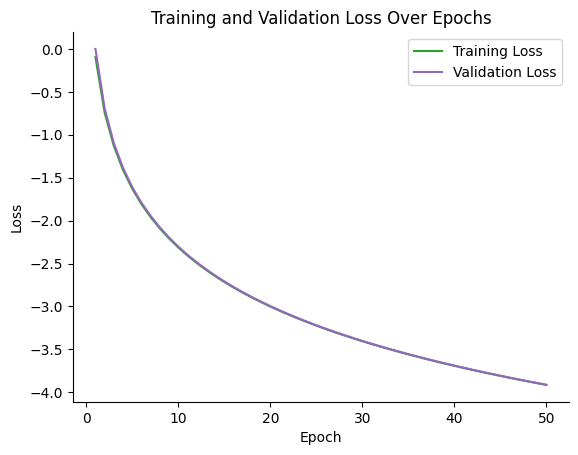

(<Figure size 640x480 with 1 Axes>,
 <Axes: title={'center': 'Training and Validation Loss Over Epochs'}, xlabel='Epoch', ylabel='Loss'>)

In [12]:
loss_plot.plot(loss_history, train_loss_color='tab:green', val_loss_color='tab:purple')

# For Development/Testing [issue#104](https://github.com/deepskies/DeepDiagnostics/issues/104) - pre-inference metrics

In [1]:
import numpy as np
import torch
from sbi.utils import BoxUniform

/home/nurs/.conda/envs/deepdiagnostics/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [6]:
num_dim = 3

# simulator represents a model with parameters (theta)
def simulator(theta):
    # linear gaussian
    return theta + 1.0 + torch.randn_like(theta) * 0.1

# prior represents what's known about the data
prior = BoxUniform(low=-2 * torch.ones(num_dim), high=2 * torch.ones(num_dim))

In [7]:
num_simulations = 5 # from sbi example, this was 2000
thetas = prior.sample((num_simulations,))
X_s = simulator(thetas) # here x represents simulated data and will be used to train the inference model
print("thetas.shape", thetas.shape)
print("X_s.shape", X_s.shape)

thetas.shape torch.Size([5, 3])
X_s.shape torch.Size([5, 3])


In [8]:
thetas

tensor([[-1.6466,  0.2464,  1.4130],
        [-0.6706,  1.7090, -1.4765],
        [-1.5794,  0.8344,  0.0035],
        [ 0.2271, -0.6946, -0.6361],
        [-0.7350,  0.2996,  0.2096]])

In [9]:
X_s

tensor([[-0.5469,  1.2555,  2.3780],
        [ 0.3589,  2.7847, -0.4276],
        [-0.5931,  1.6564,  0.9110],
        [ 1.2698,  0.1752,  0.4008],
        [ 0.2580,  1.3657,  1.2326]])

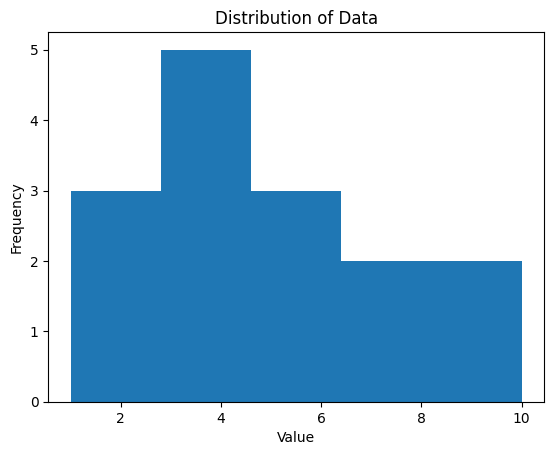

In [22]:
import matplotlib.pyplot as plt
data = [1, 2, 2, 3, 3, 3, 4, 4, 5, 6, 6, 7, 8, 9, 10]
plt.hist(data, bins=5) # Creates 5 bins for the histogram
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.title("Distribution of Data")
plt.show()

In [24]:
torch.histogram(thetas) # computes histogram

torch.return_types.histogram(
hist=tensor([1., 0., 1., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 1., 1., 1., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
        0., 2., 1., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 1., 0., 0., 0., 0., 0., 0., 0., 1.]),
bin_edges=tensor([-1.6466, -1.6130, -1.5795, -1.5459, -1.5123, -1.4788, -1.4452, -1.4117,
        -1.3781, -1.3446, -1.3110, -1.2775, -1.2439, -1.2104, -1.1768, -1.1432,
        -1.1097, -1.0761, -1.0426, -1.0090, -0.9755, -0.9419, -0.9084, -0.8748,
        -0.8412, -0.8077, -0.7741, -0.7406, -0.7070, -0.6735, -0.6399, -0.6064,
        -0.5728, -0.5392, -0.5057, -0.4721, -0.4386, -0.4050, -0.3715, -0.3379,
        -0.3044, -0.2708, -0.2372, -0.2037, -0.1701, -0.1366, -0.1030, -0.0695,
        -0.0359, -0.0024,

Text(0.5, 0, 'Bins')

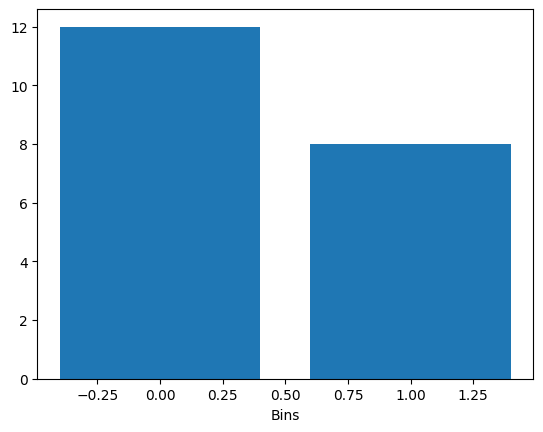

In [26]:
import torch
import matplotlib.pyplot as plt

t = torch.tensor([[0., 0., 1., 1., 0., 1., 1., 0., 0., 0.],
                  [0., 0., 1., 1., 0., 1., 1., 0., 0., 0.]])
hist = torch.histc(t, bins = 2, min = 0, max = 1)

bins = 2
x = range(bins)
plt.bar(x, hist, align='center')
plt.xlabel('Bins')

In [3]:
## based on using DeepDiagnostics package
!pwd
%cd ../resources/saveddata

/home/nurs/deepDiagnostics_RnD/DeepDiagnostics/resources/saveddata
[Errno 2] No such file or directory: '../resources/saveddata'
/home/nurs/deepDiagnostics_RnD/DeepDiagnostics/resources/saveddata


In [5]:
!ls

data_test.h5  data_train.h5  data_validation.h5


In [1]:
from deepdiagnostics.data.h5_data import H5Data
from deepdiagnostics.utils.defaults import Defaults

Defaults
# data_obj = H5Data("data_train.h5")

{'common': {'out_dir': './DeepDiagnosticsResources/results/',
  'temp_config': './DeepDiagnosticsResources/temp/temp_config.yml',
  'sim_location': './DeepDiagnosticsResources/simulators',
  'random_seed': 42},
 'model': {'model_engine': 'SBIModel'},
 'data': {'data_engine': 'H5Data',
  'prior': 'normal',
  'prior_kwargs': None,
  'simulator_kwargs': None,
  'simulator_dimensions': 1},
 'plots_common': {'axis_spines': False,
  'tight_layout': True,
  'default_colorway': 'viridis',
  'plot_style': 'fast',
  'parameter_labels': ['$m$', '$b$'],
  'parameter_colors': ['#9C92A3', '#0F5257'],
  'line_style_cycle': ['-', '-.'],
  'figure_size': [6, 6]},
 'plots': {'CDFRanks': {},
  'Ranks': {'num_bins': None},
  'CoverageFraction': {},
  'TARP': {'coverage_sigma': 3},
  'LC2ST': {},
  'Parity': {},
  'PPC': {},
  'PriorPC': {}},
 'metrics_common': {'use_progress_bar': False,
  'samples_per_inference': 1000,
  'percentiles': [75, 85, 95],
  'number_simulations': 50},
 'metrics': {'AllSBC': {},

In [2]:
!pwd

/home/nurs/deepDiagnostics_RnD/DeepDiagnostics/notebooks


In [7]:
%%writefile my_simulator.py 

from deepdiagnostics.data.simulator import Simulator
import numpy as np 

class MySimulator(Simulator): 
    def generate_context(self, n_samples: int=101) -> np.ndarray:
        return np.linspace(0, 100, n_samples)
        # return np.random.uniform(0, 1)
    
    def simulate(self, theta: np.ndarray, context_samples: np.ndarray) -> np.ndarray:
        thetas = np.atleast_2d(theta)
        if thetas.shape[1] != 2:
            raise ValueError("Input tensor must have shape (n, 2) where n is the number of parameter sets.")

        if thetas.shape[0] == 1:
            # If there's only one set of parameters, extract them directly
            m, b = thetas[0, 0], thetas[0, 1]
        else:
            # If there are multiple sets of parameters, extract them for each row
            m, b = thetas[:, 0], thetas[:, 1]
        rs = np.random.RandomState()
        sigma = 1
        epsilon = rs.normal(loc=0, scale=sigma, size=(len(context_samples), thetas.shape[0]))
        
        # Initialize an empty array to store the results for each set of parameters
        y = np.zeros((len(context_samples), thetas.shape[0]))
        for i in range(thetas.shape[0]):
            m, b = thetas[i, 0], thetas[i, 1]
            y[:, i] = m * context_samples + b + epsilon[:, i]
        return y.T

Overwriting my_simulator.py


In [8]:
# Just running the file to make sure we're not either missing imports or have a syntax error
! python3 my_simulator.py

In [9]:
from my_simulator import MySimulator
from deepdiagnostics.utils.simulator_utils import register_simulator


mysim = MySimulator()
mysim.generate_context(10) # prior
# register_simulator("MySimulator", MySimulator) 
# We are registering without having a config set ahead of time, so it may raise a warning. This is fine!
# Only reason we'd want to use a config ahead of time is if we were running this in a cluster 
# And had specific requirements where we can put files 
# In which case we'd change the "common":{"sim_location": <path>} field

0.7548908454527327

In [16]:
num_simulations = 5 # from sbi example, this was 2000
thetas = mysim.sample((num_simulations,))

AttributeError: 'MySimulator' object has no attribute 'sample'

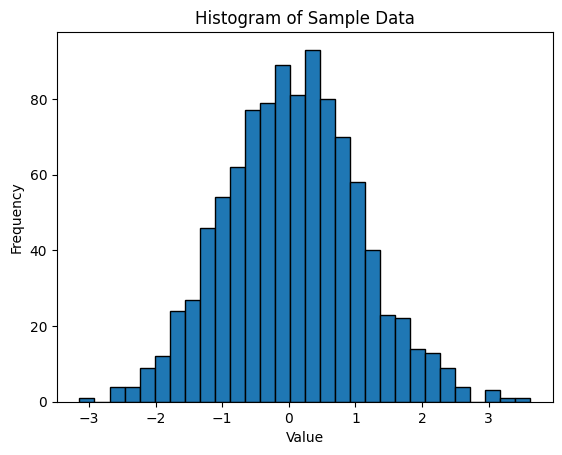

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# Generate some sample data (e.g., a normal distribution)
data = np.random.randn(1000)

# Create the histogram
plt.hist(data, bins=30, edgecolor='black') # bins specifies the number of bins, edgecolor adds borders

# Add labels and a title
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.title("Histogram of Sample Data")

# Display the plot
plt.show()

/home/nurs/.conda/envs/deepdiagnostics/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


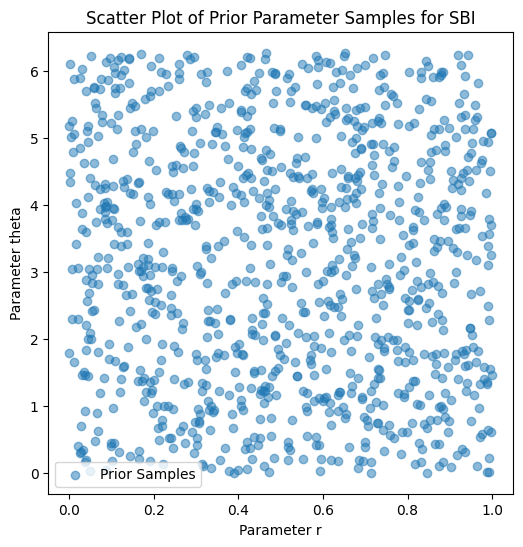

In [4]:
import torch
from sbi.utils import BoxUniform
from sbi import utils as sbiutils
from matplotlib import pyplot as plt

# 1. Define the simulator and prior
# This function defines the simple 2D simulation
def simulator(theta):
    r, theta_angle = theta
    center_x = r * torch.cos(theta_angle)
    center_y = r * torch.sin(theta_angle)
    
    # Generate 100 noisy 2D points
    n_points = 100
    noise = 0.01 * torch.randn(n_points, 2)
    
    simulation_output = torch.zeros(n_points, 2)
    for i in range(n_points):
        simulation_output[i] = torch.tensor([center_x, center_y]) + noise[i]
        
    return simulation_output

# Define the prior distributions for the parameters
prior = BoxUniform(low=torch.zeros(2), high=torch.tensor([1, 2*torch.pi]))

# 2. Generate simulated data
num_simulations = 1000
prior_samples = prior.sample((num_simulations,))
all_simulations = []
for theta in prior_samples:
    all_simulations.append(simulator(theta))
all_simulations = torch.stack(all_simulations)

# 3. Create the scatter plot
fig, ax = plt.subplots(1, 1, figsize=(6, 6))

# Plot the sampled parameter values from the prior
ax.scatter(prior_samples[:, 0], prior_samples[:, 1], alpha=0.5, label='Prior Samples')

# Set labels and title
ax.set_xlabel("Parameter r")
ax.set_ylabel("Parameter theta")
ax.set_title("Scatter Plot of Prior Parameter Samples for SBI")
ax.legend()

plt.show()


### pytorch level code testing for simulator

In [13]:
thetas[0]

tensor([-0.9872,  2.8468,  2.8308])

In [7]:
thetas[0] + 1.0

tensor([-0.9872,  2.8468,  2.8308])

In [9]:
torch.randn_like(thetas[0])

tensor([-0.4359, -0.7494,  0.0545])

In [10]:
torch.randn_like(thetas[0]) * 0.1

tensor([ 0.1232, -0.1232,  0.0569])